In [1]:
# Impor pustaka untuk pengolahan data, visualisasi, dan pencatatan eksperimen.
from pathlib import Path
import json
import shutil

import joblib
import mlflow
import mlflow.sklearn
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

c:\Users\MSI-GF63\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Impor komponen preprocessing, model, evaluasi, dan validasi silang.
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, classification_report, ConfusionMatrixDisplay,
    f1_score, log_loss, precision_score, PrecisionRecallDisplay,
    recall_score, roc_auc_score, RocCurveDisplay,
)
from sklearn.model_selection import cross_validate, RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [3]:
# Tetapkan konfigurasi, label target, dan folder keluaran.
RANDOM_STATE = 42
DATASET = "architsharma01/loan-approval-prediction-dataset"
TARGET = "loan_status"
TARGET_MAP = {"rejected": 0, "approved": 1}
LABEL_MAP = {0: "Rejected", 1: "Approved"}
DATA_DIR = Path("data")
ARTIFACT_DIR = Path("artifacts")
DATA_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

In [4]:
# Simpan metadata eksperimen pada database SQLite lokal.
MLFLOW_DB = Path("mlflow.db").resolve()
MLFLOW_URI = f"sqlite:///{MLFLOW_DB}"
mlflow.set_tracking_uri(MLFLOW_URI)
mlflow_experiment = mlflow.set_experiment("loan-approval-prediction")

# Bersihkan run lama agar eksperimen hanya menampilkan satu hasil terbaru.
old_runs = mlflow.search_runs(experiment_ids=[mlflow_experiment.experiment_id])
for old_run_id in old_runs.get("run_id", []):
    mlflow.delete_run(old_run_id)


2026/11/07 18:43:46 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/07 18:43:46 INFO mlflow.store.db.utils: Updating database tables
2026/11/07 18:43:48 INFO mlflow.tracking.fluent: Experiment with name 'loan-approval-prediction' does not exist. Creating a new experiment.


In [5]:
print({"mlflow_version": mlflow.__version__, "tracking_uri": mlflow.get_tracking_uri(), "experiment_id": mlflow_experiment.experiment_id})


{'mlflow_version': '3.16.1', 'tracking_uri': 'sqlite:///D:\\Python\\AI_Loan_prediction_Project\\mlflow.db', 'experiment_id': '1'}


In [6]:
# Unduh dataset jika belum tersedia, lalu baca dan tinjau isinya.

csv_path = DATA_DIR / "loan_approval_dataset.csv"
if not csv_path.exists():
    dataset_dir = Path(kagglehub.dataset_download(DATASET))
    source_csv = next(dataset_dir.rglob("loan_approval_dataset.csv"))
    shutil.copy2(source_csv, csv_path)

# Baca dataset dan tampilkan cuplikan serta skema kolom.
raw_df = pd.read_csv(csv_path)
display(raw_df.head(10))
print(raw_df.shape)
raw_df.info()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
5,6,0,Graduate,Yes,4800000,13500000,10,319,6800000,8300000,13700000,5100000,Rejected
6,7,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
7,8,2,Graduate,Yes,5700000,15000000,20,382,13200000,5700000,11800000,6000000,Rejected
8,9,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
9,10,5,Not Graduate,No,1100000,4300000,10,388,3200000,1400000,3300000,1600000,Rejected


(4269, 13)
<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   loan_id                    4269 non-null   int64
 1    no_of_dependents          4269 non-null   int64
 2    education                 4269 non-null   str  
 3    self_employed             4269 non-null   str  
 4    income_annum              4269 non-null   int64
 5    loan_amount               4269 non-null   int64
 6    loan_term                 4269 non-null   int64
 7    cibil_score               4269 non-null   int64
 8    residential_assets_value  4269 non-null   int64
 9    commercial_assets_value   4269 non-null   int64
 10   luxury_assets_value       4269 non-null   int64
 11   bank_asset_value          4269 non-null   int64
 12   loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 531.6 KB


In [7]:
# Periksa tipe data, nilai kosong, duplikasi, dan ringkasan dataset.

raw_quality = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "missing_count": raw_df.isna().sum(),
    "missing_percent": raw_df.isna().mean().mul(100),
    "unique_count": raw_df.nunique(dropna=False),
})

# Tampilkan ringkasan kualitas dan statistik dataset.
display(raw_quality)
display(raw_df.describe(include="all").T)
display(pd.Series({
    "rows": len(raw_df),
    "columns": raw_df.shape[1],
    "exact_duplicate_rows": int(raw_df.duplicated().sum()),
    "empty_rows": int(raw_df.isna().all(axis=1).sum()),
    "whitespace_column_names": int(sum(name != name.strip() for name in raw_df.columns)),
}))

,dtype,missing_count,missing_percent,unique_count
loan_id,int64,0,0.0000,4269
no_of_dependents,int64,0,0.0000,6
education,str,0,0.0000,2
self_employed,str,0,0.0000,2
income_annum,int64,0,0.0000,98
loan_amount,int64,0,0.0000,378
loan_term,int64,0,0.0000,10
cibil_score,int64,0,0.0000,601
residential_assets_value,int64,0,0.0000,278
commercial_assets_value,int64,0,0.0000,188


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
loan_id,"4,269.0000",NaN,NaN,NaN,"2,135.0000","1,232.4985",1.0000,"1,068.0000","2,135.0000","3,202.0000","4,269.0000"
no_of_dependents,"4,269.0000",NaN,NaN,NaN,2.4987,1.6959,0.0000,1.0000,3.0000,4.0000,5.0000
education,4269,2,Graduate,2144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
self_employed,4269,2,Yes,2150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_annum,"4,269.0000",NaN,NaN,NaN,"5,059,123.9166","2,806,839.8318","200,000.0000","2,700,000.0000","5,100,000.0000","7,500,000.0000","9,900,000.0000"
loan_amount,"4,269.0000",NaN,NaN,NaN,"15,133,450.4568","9,043,362.9848","300,000.0000","7,700,000.0000","14,500,000.0000","21,500,000.0000","39,500,000.0000"
loan_term,"4,269.0000",NaN,NaN,NaN,10.9004,5.7092,2.0000,6.0000,10.0000,16.0000,20.0000
cibil_score,"4,269.0000",NaN,NaN,NaN,599.9361,172.4304,300.0000,453.0000,600.0000,748.0000,900.0000
residential_assets_value,"4,269.0000",NaN,NaN,NaN,"7,472,616.5378","6,503,636.5877","-100,000.0000","2,200,000.0000","5,600,000.0000","11,300,000.0000","29,100,000.0000"
commercial_assets_value,"4,269.0000",NaN,NaN,NaN,"4,973,155.3057","4,388,966.0896",0.0000,"1,300,000.0000","3,700,000.0000","7,600,000.0000","19,400,000.0000"


rows                       4269
columns                      13
exact_duplicate_rows          0
empty_rows                    0
whitespace_column_names      12
dtype: int64

In [8]:
# Daftarkan fitur numerik, kategori, aset, dan kolom target.
numeric_columns = [
    "no_of_dependents", "income_annum", "loan_amount", "loan_term", "cibil_score",
    "residential_assets_value", "commercial_assets_value", "luxury_assets_value", "bank_asset_value",
]
categorical_columns = ["education", "self_employed"]
asset_columns = [
    "residential_assets_value", "commercial_assets_value", "luxury_assets_value", "bank_asset_value",
]
expected_columns = ["loan_id", *numeric_columns, *categorical_columns, TARGET]

In [9]:
# Rapikan nama kolom dan pastikan seluruh kolom wajib tersedia.

normalized_df = raw_df.copy()
normalized_df.columns = normalized_df.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True)

# Validasi nama kolom agar tidak ada kolom ganda.
if normalized_df.columns.duplicated().any():
    raise ValueError("Duplicate column names after normalization")
missing_columns = set(expected_columns) - set(normalized_df.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

In [10]:
# Seragamkan nilai teks dan ubah penanda kosong menjadi missing.
for column in [*categorical_columns, TARGET]:
    normalized_df[column] = normalized_df[column].map(
        lambda value: value.strip().lower() if isinstance(value, str) else value
    )
    normalized_df[column] = normalized_df[column].replace({"": np.nan, "nan": np.nan, "null": np.nan, "none": np.nan})

In [11]:
# Konversi fitur numerik dan catat nilai yang gagal dikonversi.

conversion_audit = []

# Konversi setiap fitur numerik dan rekam kegagalannya.
for column in numeric_columns:
    original = normalized_df[column]
    converted = pd.to_numeric(original, errors="coerce").replace([np.inf, -np.inf], np.nan)
    conversion_audit.append({
        "feature": column,
        "invalid_numeric_to_missing": int((original.notna() & converted.isna()).sum()),
    })
    normalized_df[column] = converted

In [12]:
display(pd.DataFrame(conversion_audit))
for column in [*categorical_columns, TARGET]:
    display(normalized_df[column].value_counts(dropna=False).rename_axis(column).to_frame("count"))

,feature,invalid_numeric_to_missing
0,no_of_dependents,0
1,income_annum,0
2,loan_amount,0
3,loan_term,0
4,cibil_score,0
5,residential_assets_value,0
6,commercial_assets_value,0
7,luxury_assets_value,0
8,bank_asset_value,0


,count
education,
graduate,2144
not graduate,2125


,count
self_employed,
yes,2150
no,2119


,count
loan_status,
approved,2656
rejected,1613


In [13]:
# Tentukan kategori yang valid untuk setiap fitur teks.
allowed_categories = {"education": {"graduate", "not graduate"}, "self_employed": {"yes", "no"}}
invalid_masks = {}

In [14]:
# Tandai nilai numerik yang berada di luar aturan validasi.

for column in numeric_columns:
    invalid_masks[column] = normalized_df[column] < 0

# Terapkan batas nilai khusus untuk pinjaman dan pendapatan.
for column in ["income_annum", "loan_amount", "loan_term"]:
    invalid_masks[column] = normalized_df[column] <= 0
invalid_masks["cibil_score"] = normalized_df["cibil_score"].notna() & ~normalized_df["cibil_score"].between(300, 900)
invalid_masks["no_of_dependents"] = (
    normalized_df["no_of_dependents"].lt(0)
    | normalized_df["no_of_dependents"].mod(1).ne(0) & normalized_df["no_of_dependents"].notna()
)

In [15]:
for column, allowed in allowed_categories.items():
    invalid_masks[column] = normalized_df[column].notna() & ~normalized_df[column].isin(allowed)

In [16]:
# Ringkas jumlah nilai tidak valid pada setiap fitur.
invalid_audit = pd.DataFrame([
    {"feature": column, "invalid_count": int(mask.sum())}
    for column, mask in invalid_masks.items()
]).sort_values("invalid_count", ascending=False)
display(invalid_audit)

,feature,invalid_count
5,residential_assets_value,28
1,income_annum,0
0,no_of_dependents,0
2,loan_amount,0
3,loan_term,0
4,cibil_score,0
6,commercial_assets_value,0
7,luxury_assets_value,0
8,bank_asset_value,0
9,education,0


In [17]:
# Tinjau baris bermasalah serta duplikasi berdasarkan ID dan isi.
invalid_rows_mask = pd.DataFrame(invalid_masks).any(axis=1)
display(normalized_df.loc[invalid_rows_mask].head(20))
display(pd.Series({
    "duplicate_loan_ids": int(normalized_df["loan_id"].duplicated().sum()),
    "duplicate_records_without_id": int(normalized_df.drop(columns="loan_id").duplicated().sum()),
}))

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
59,60,4,not graduate,yes,5500000,18200000,16,797,-100000,4900000,18600000,4800000,approved
196,197,4,not graduate,yes,400000,1500000,2,669,-100000,600000,900000,500000,approved
559,560,2,graduate,yes,200000,500000,6,885,-100000,0,300000,200000,rejected
702,703,4,graduate,yes,6300000,23900000,6,899,-100000,11400000,20600000,6700000,approved
737,738,2,graduate,yes,900000,2500000,16,458,-100000,100000,3200000,1100000,rejected
784,785,0,graduate,no,5000000,14400000,2,761,-100000,7300000,12600000,4500000,approved
904,905,2,graduate,no,4100000,14900000,12,571,-100000,5200000,13000000,3400000,approved
1089,1090,3,graduate,no,5100000,11000000,6,336,-100000,5800000,11600000,7500000,rejected
1163,1164,2,graduate,no,4500000,9100000,18,593,-100000,600000,12400000,2500000,approved
1350,1351,5,graduate,no,4000000,13700000,6,496,-100000,1400000,15800000,3700000,rejected


duplicate_loan_ids              0
duplicate_records_without_id    0
dtype: int64

In [18]:
# Bersihkan nilai tidak valid dengan mengubahnya menjadi missing.

clean_df = normalized_df.copy()
cleaning_log = [{"operation": "input_rows", "count": len(clean_df)}]

# Ubah nilai yang tidak valid menjadi missing.
for column, mask in invalid_masks.items():
    clean_df.loc[mask, column] = np.nan

In [19]:
# Hapus baris tanpa target dan periksa label target yang dikenal.
unknown_targets = clean_df[TARGET].notna() & ~clean_df[TARGET].isin(TARGET_MAP)
if unknown_targets.any():
    raise ValueError(f"Unexpected target labels: {clean_df.loc[unknown_targets, TARGET].unique().tolist()}")
missing_target_count = int(clean_df[TARGET].isna().sum())
clean_df = clean_df.dropna(subset=[TARGET])
cleaning_log.append({"operation": "missing_target_rows_removed", "count": missing_target_count})

In [20]:
# Hapus catatan duplikat dan lengkapi log pembersihan.

record_columns = [column for column in clean_df.columns if column != "loan_id"]
duplicate_count = int(clean_df.duplicated(subset=record_columns).sum())
clean_df = clean_df.drop_duplicates(subset=record_columns).reset_index(drop=True)

# Catat jumlah baris yang dibuang dan hasil pembersihan.
cleaning_log.append({"operation": "duplicate_records_removed", "count": duplicate_count})
cleaning_log.append({"operation": "invalid_cells_to_missing", "count": int(invalid_audit["invalid_count"].sum())})
cleaning_log.append({"operation": "output_rows", "count": len(clean_df)})

In [21]:
# Simpan dataset bersih beserta audit proses pembersihannya.

cleaning_log = pd.DataFrame(cleaning_log)

# Tinjau hasil pembersihan sebelum menyimpan berkas.
display(cleaning_log)
display(pd.DataFrame({
    "missing_before": normalized_df.isna().sum(),
    "missing_after": clean_df.isna().sum(),
    "dtype_after": clean_df.dtypes.astype(str),
}))
clean_df.to_csv(DATA_DIR / "loan_approval_cleaned.csv", index=False)
cleaning_log.to_csv(ARTIFACT_DIR / "cleaning_log.csv", index=False)
invalid_audit.to_csv(ARTIFACT_DIR / "invalid_value_audit.csv", index=False)

,operation,count
0,input_rows,4269
1,missing_target_rows_removed,0
2,duplicate_records_removed,0
3,invalid_cells_to_missing,28
4,output_rows,4269


,missing_before,missing_after,dtype_after
loan_id,0,0,int64
no_of_dependents,0,0,float64
education,0,0,str
self_employed,0,0,str
income_annum,0,0,float64
loan_amount,0,0,float64
loan_term,0,0,float64
cibil_score,0,0,float64
residential_assets_value,0,28,float64
commercial_assets_value,0,0,float64


In [22]:
# Pisahkan data latih dan uji secara stratifikasi sebelum analisis.

X_raw = clean_df.drop(columns=[TARGET, "loan_id"])
y = clean_df[TARGET].map(TARGET_MAP).astype("int8")
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Siapkan data latih untuk analisis eksploratif.
eda_df = X_train_raw.copy()
eda_df[TARGET] = y_train.map(LABEL_MAP)

display(pd.DataFrame({
    "train_count": y_train.map(LABEL_MAP).value_counts(),
    "test_count": y_test.map(LABEL_MAP).value_counts(),
    "train_percent": y_train.map(LABEL_MAP).value_counts(normalize=True).mul(100),
    "test_percent": y_test.map(LABEL_MAP).value_counts(normalize=True).mul(100),
}))
display(eda_df.describe(include="all").T)

,train_count,test_count,train_percent,test_percent
loan_status,,,,
Approved,2125,531,62.2255,62.1780
Rejected,1290,323,37.7745,37.8220


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
no_of_dependents,"3,415.0000",NaN,NaN,NaN,2.4893,1.6963,0.0000,1.0000,3.0000,4.0000,5.0000
education,3415,2,graduate,1710,NaN,NaN,NaN,NaN,NaN,NaN,NaN
self_employed,3415,2,yes,1722,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_annum,"3,415.0000",NaN,NaN,NaN,"5,058,711.5666","2,792,881.4824","200,000.0000","2,700,000.0000","5,100,000.0000","7,400,000.0000","9,900,000.0000"
loan_amount,"3,415.0000",NaN,NaN,NaN,"15,091,478.7701","8,926,745.7836","300,000.0000","7,800,000.0000","14,600,000.0000","21,300,000.0000","38,800,000.0000"
loan_term,"3,415.0000",NaN,NaN,NaN,10.8750,5.7310,2.0000,6.0000,10.0000,16.0000,20.0000
cibil_score,"3,415.0000",NaN,NaN,NaN,599.4114,172.9439,300.0000,450.0000,598.0000,749.0000,900.0000
residential_assets_value,"3,396.0000",NaN,NaN,NaN,"7,451,442.8740","6,412,823.1930",0.0000,"2,200,000.0000","5,600,000.0000","11,200,000.0000","29,100,000.0000"
commercial_assets_value,"3,415.0000",NaN,NaN,NaN,"4,967,174.2313","4,368,132.6630",0.0000,"1,300,000.0000","3,700,000.0000","7,600,000.0000","19,400,000.0000"
luxury_assets_value,"3,415.0000",NaN,NaN,NaN,"15,139,824.3045","9,091,030.2957","300,000.0000","7,500,000.0000","14,600,000.0000","21,600,000.0000","39,200,000.0000"


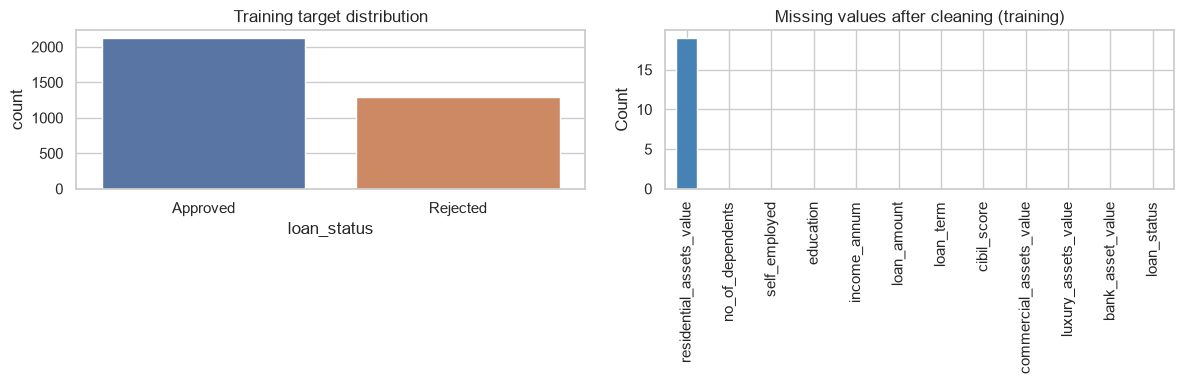

In [23]:
# Visualisasikan distribusi target dan nilai kosong pada data latih.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=eda_df, x=TARGET, hue=TARGET, legend=False, ax=axes[0])
axes[0].set_title("Training target distribution")
missing = eda_df.isna().sum().sort_values(ascending=False)
missing.plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title("Missing values after cleaning (training)")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

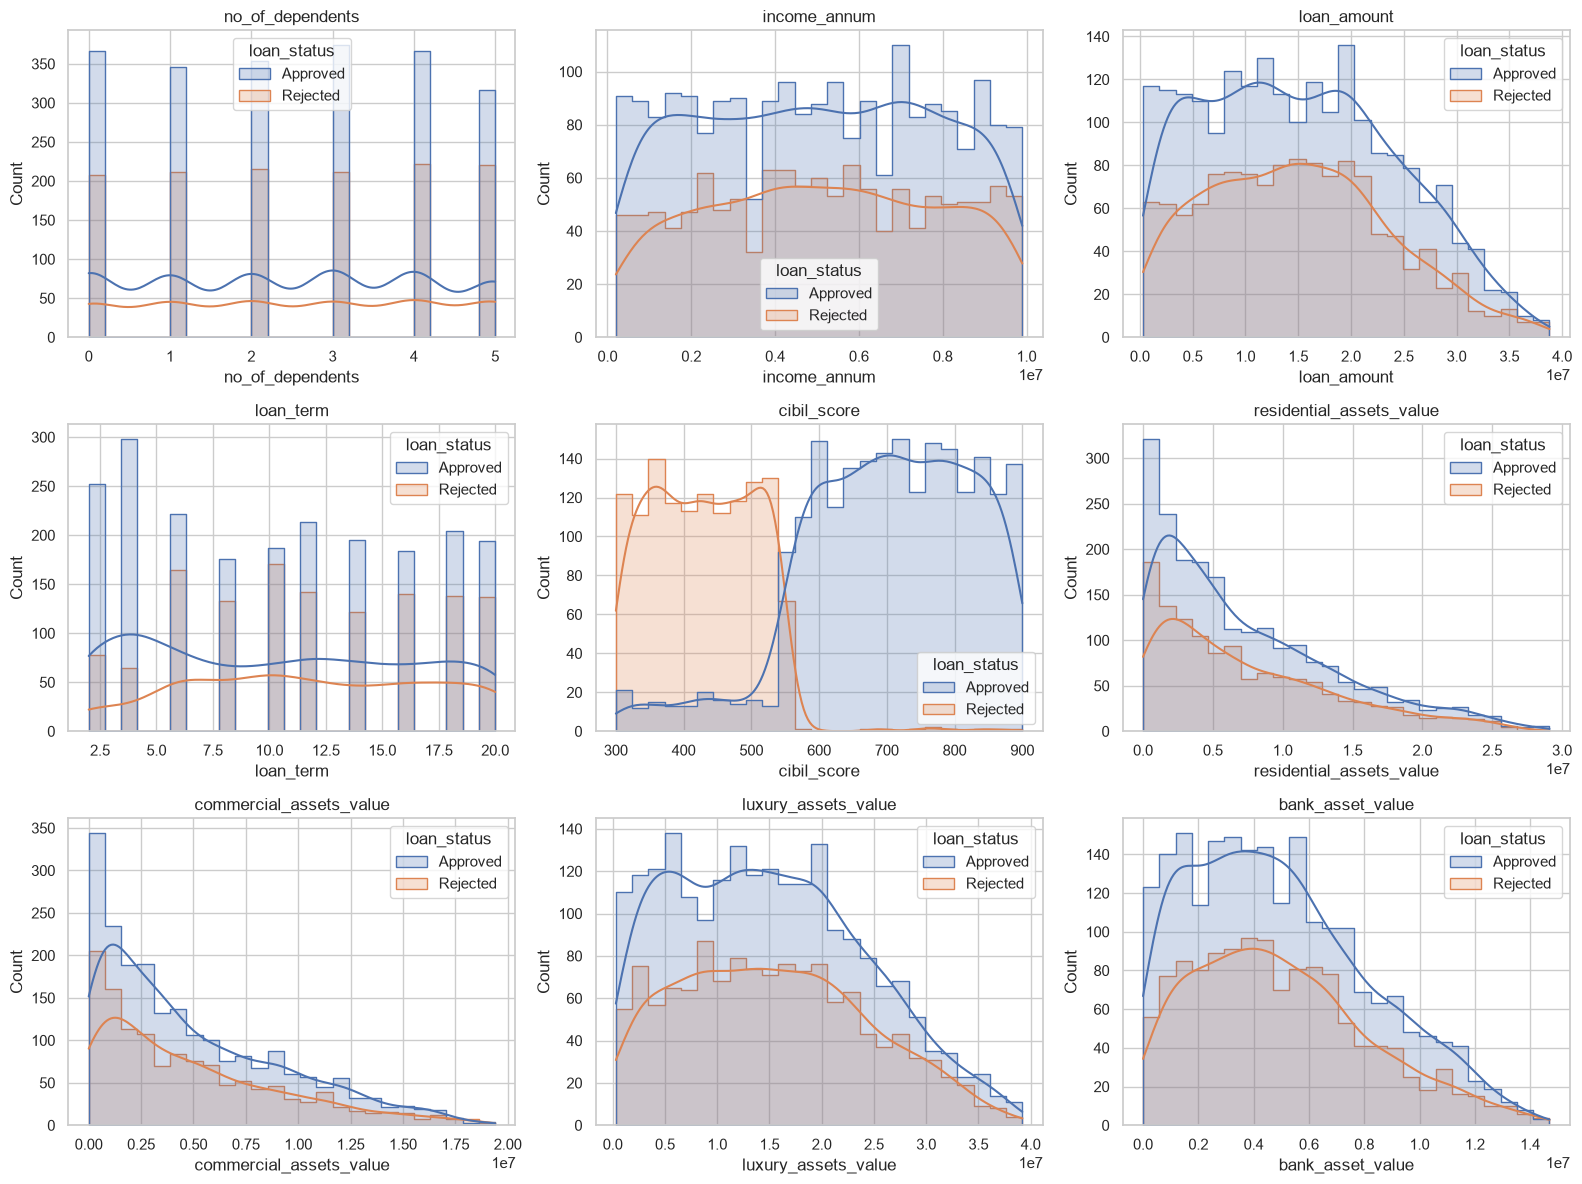

In [24]:
# Bandingkan distribusi fitur numerik menurut status pinjaman.
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for column, ax in zip(numeric_columns, axes.flat):
    sns.histplot(data=eda_df, x=column, hue=TARGET, bins=25, kde=True, element="step", ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

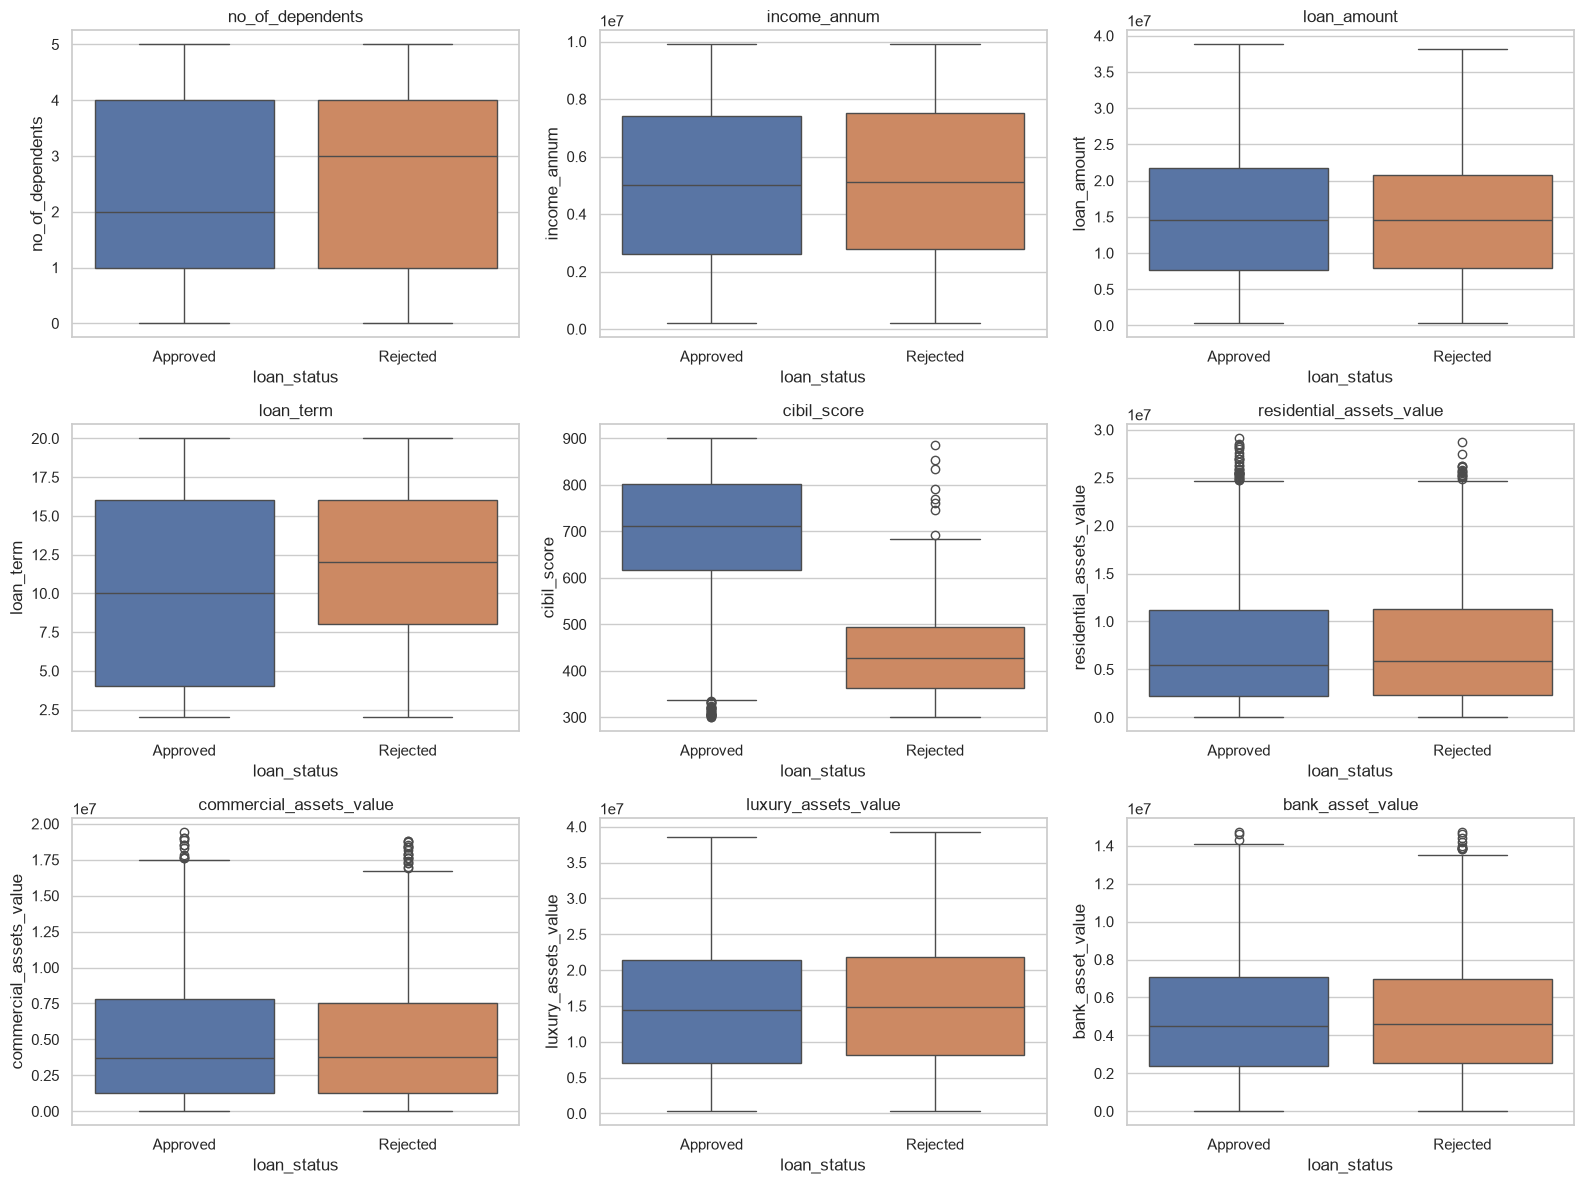

,feature,q1,q3,lower_bound,upper_bound,iqr_flag_count,iqr_flag_percent,skewness
0,no_of_dependents,1.0000,4.0000,-3.5000,8.5000,0,0.0000,-0.0092
1,income_annum,"2,700,000.0000","7,400,000.0000","-4,350,000.0000","14,450,000.0000",0,0.0000,-0.0099
2,loan_amount,"7,800,000.0000","21,300,000.0000","-12,450,000.0000","41,550,000.0000",0,0.0000,0.3003
3,loan_term,6.0000,16.0000,-9.0000,31.0000,0,0.0000,0.0437
4,cibil_score,450.0000,749.0000,1.5000,"1,197.5000",0,0.0000,-0.0073
5,residential_assets_value,"2,200,000.0000","11,200,000.0000","-11,300,000.0000","24,700,000.0000",45,1.3177,0.9841
6,commercial_assets_value,"1,300,000.0000","7,600,000.0000","-8,150,000.0000","17,050,000.0000",33,0.9663,0.9640
7,luxury_assets_value,"7,500,000.0000","21,600,000.0000","-13,650,000.0000","42,750,000.0000",0,0.0000,0.3360
8,bank_asset_value,"2,400,000.0000","7,000,000.0000","-4,500,000.0000","13,900,000.0000",13,0.3807,0.5757


In [25]:
# Tinjau pencilan dengan aturan IQR tanpa menghapus nilai ekstrem.

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for column, ax in zip(numeric_columns, axes.flat):
    sns.boxplot(data=eda_df, x=TARGET, y=column, hue=TARGET, legend=False, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

# Hitung batas IQR dan jumlah pencilan tiap fitur.
outlier_rows = []
for column in numeric_columns:
    q1, q3 = X_train_raw[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = X_train_raw[column].lt(lower) | X_train_raw[column].gt(upper)
    outlier_rows.append({
        "feature": column, "q1": q1, "q3": q3,
        "lower_bound": lower, "upper_bound": upper,
        "iqr_flag_count": int(mask.sum()),
        "iqr_flag_percent": float(mask.mean() * 100),
        "skewness": X_train_raw[column].skew(),
    })
outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)
outlier_report.to_csv(ARTIFACT_DIR / "training_outlier_report.csv", index=False)

loan_status,Approved,Rejected,All
education,,,
graduate,1069,641,1710
not graduate,1056,649,1705
All,2125,1290,3415


loan_status,Approved,Rejected
education,,
graduate,62.5146,37.4854
not graduate,61.9355,38.0645


loan_status,Approved,Rejected,All
self_employed,,,
no,1047,646,1693
yes,1078,644,1722
All,2125,1290,3415


loan_status,Approved,Rejected
self_employed,,
no,61.8429,38.1571
yes,62.6016,37.3984


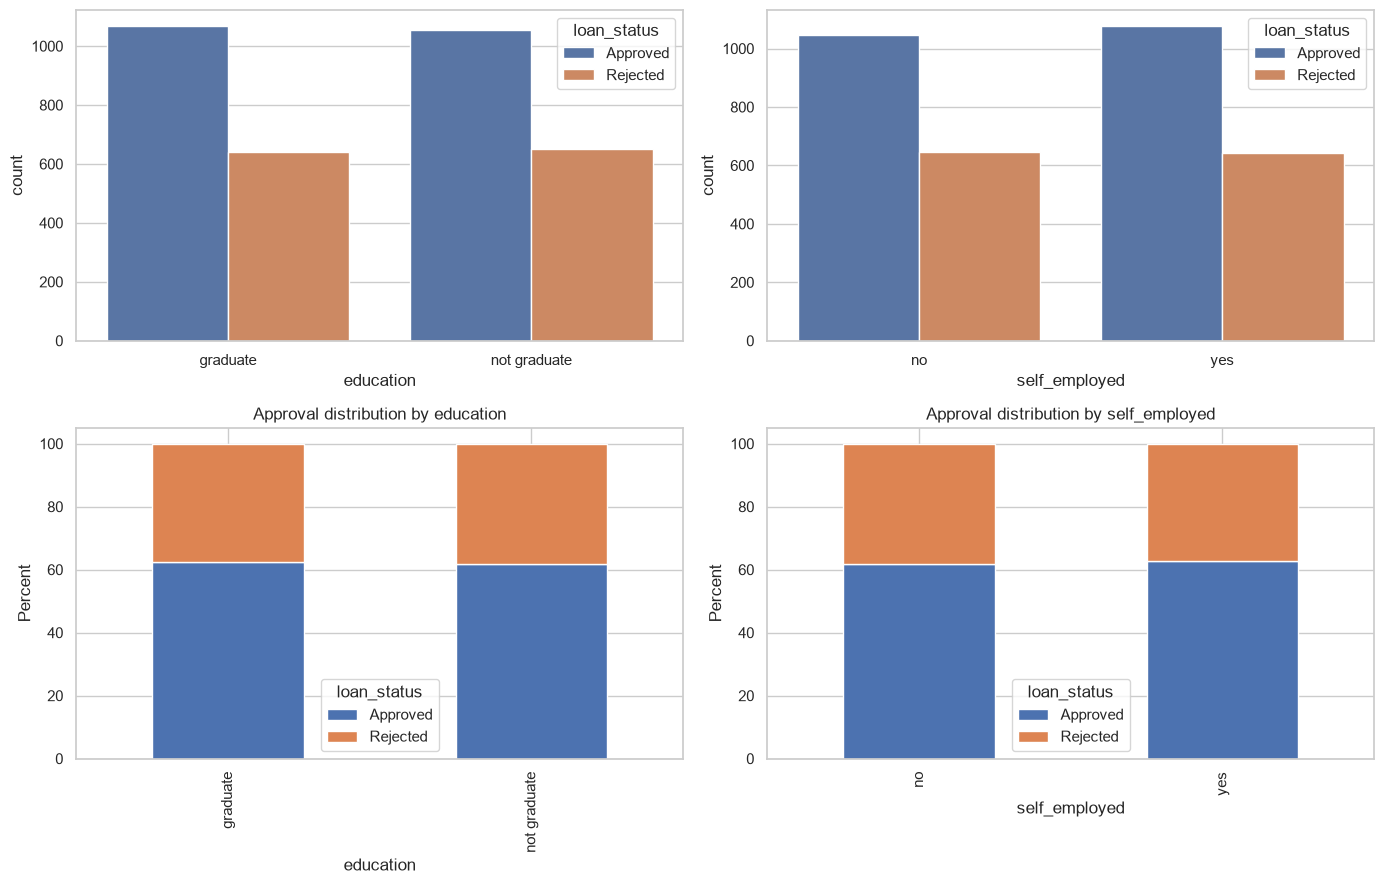

In [26]:
# Bandingkan kategori dan tingkat persetujuan pada data latih.

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Bandingkan komposisi kategori dan persentase persetujuan.
for column, count_ax, rate_ax in zip(categorical_columns, axes[0], axes[1]):
    sns.countplot(data=eda_df, x=column, hue=TARGET, ax=count_ax)
    rates = pd.crosstab(eda_df[column], eda_df[TARGET], normalize="index").mul(100)
    rates.plot.bar(stacked=True, ax=rate_ax)
    rate_ax.set_ylabel("Percent")
    rate_ax.set_title(f"Approval distribution by {column}")
    display(pd.crosstab(eda_df[column], eda_df[TARGET], margins=True))
    display(rates)
plt.tight_layout()
plt.show()

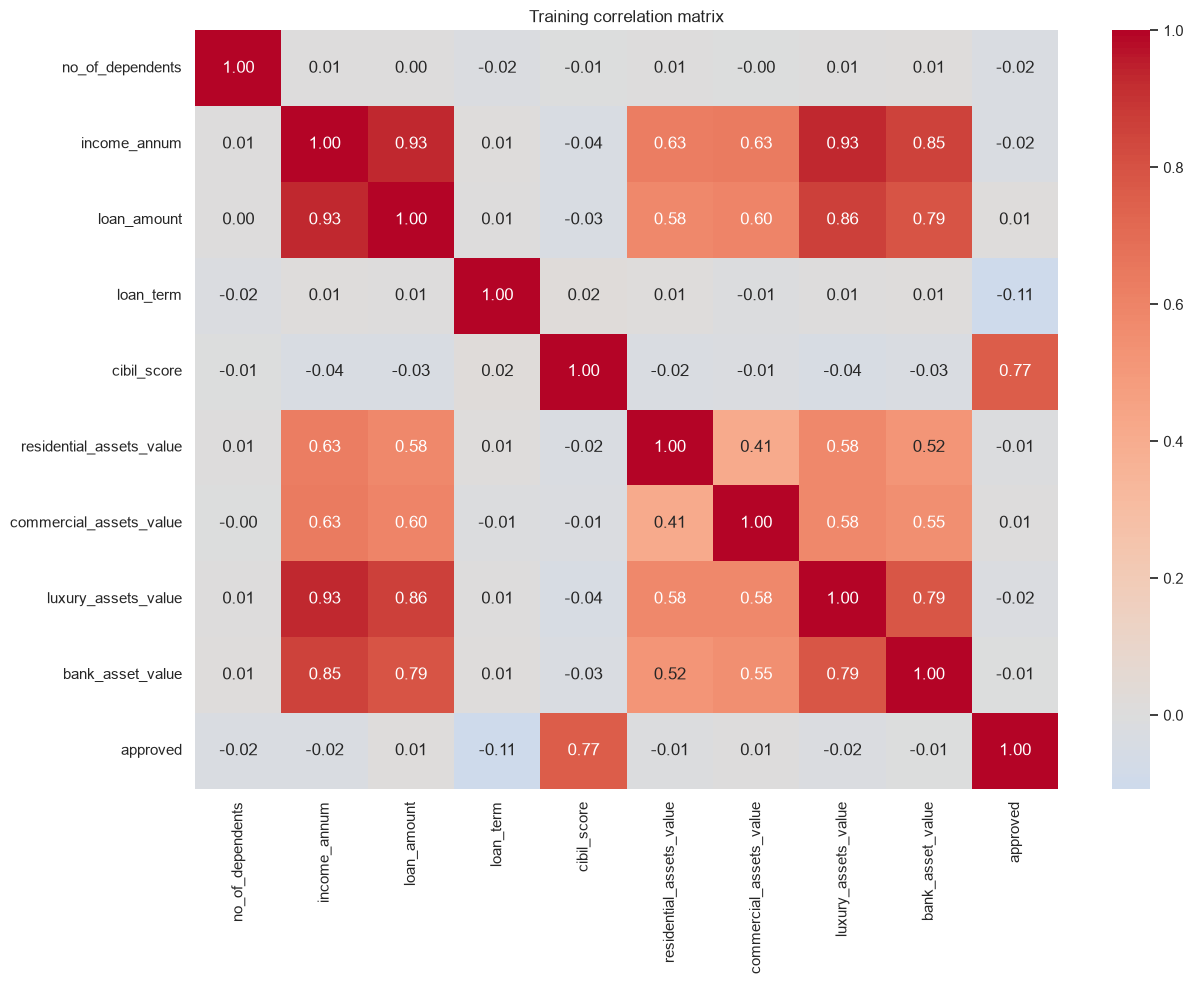

,target_correlation
cibil_score,0.7662
loan_amount,0.0131
commercial_assets_value,0.0052
bank_asset_value,-0.0081
residential_assets_value,-0.0099
luxury_assets_value,-0.0203
income_annum,-0.0214
no_of_dependents,-0.0216
loan_term,-0.1076


In [27]:
# Tampilkan korelasi antarfitur numerik dan target.
correlation_data = X_train_raw[numeric_columns].copy()
correlation_data["approved"] = y_train
plt.figure(figsize=(13, 10))
sns.heatmap(correlation_data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Training correlation matrix")
plt.tight_layout()
plt.show()
display(correlation_data.corr()["approved"].drop("approved").sort_values(ascending=False).to_frame("target_correlation"))

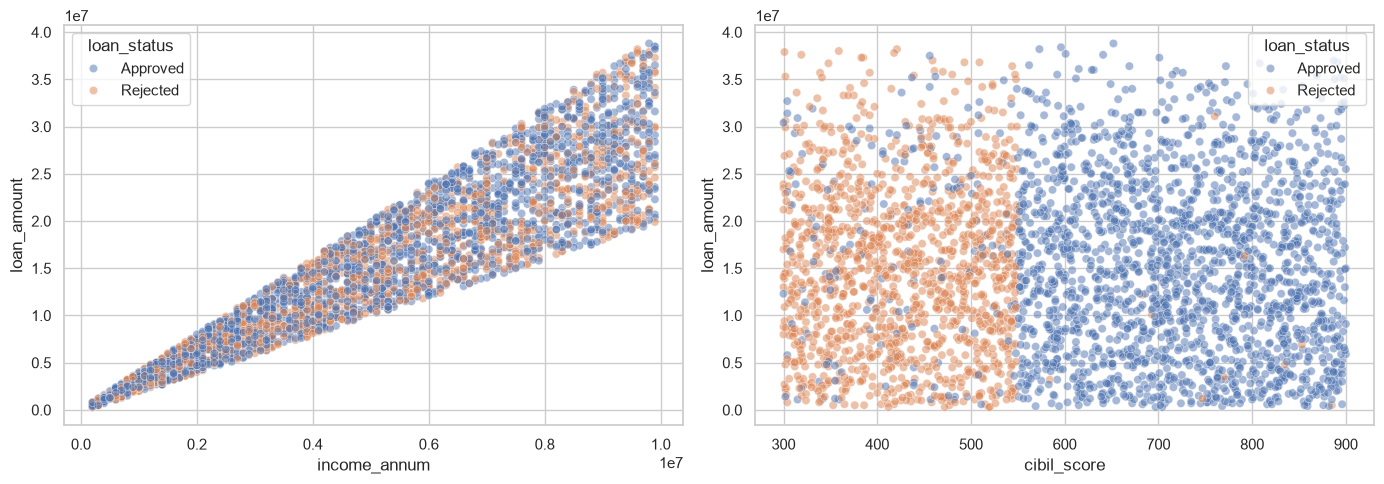

In [28]:
# Lihat hubungan pendapatan, jumlah pinjaman, dan skor kredit.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=eda_df, x="income_annum", y="loan_amount", hue=TARGET, alpha=0.5, ax=axes[0])
sns.scatterplot(data=eda_df, x="cibil_score", y="loan_amount", hue=TARGET, alpha=0.5, ax=axes[1])
plt.tight_layout()
plt.show()

In [29]:
# Buat fitur turunan dan pisahkan daftar fitur untuk preprocessing.

def engineer_features(frame):
    result = frame.copy()
    result["total_assets_value"] = result[asset_columns].sum(axis=1, min_count=len(asset_columns))
    result["loan_to_income_ratio"] = result["loan_amount"].div(result["income_annum"].replace(0, np.nan))
    result["assets_to_loan_ratio"] = result["total_assets_value"].div(result["loan_amount"].replace(0, np.nan))
    result["loan_amount_per_term"] = result["loan_amount"].div(result["loan_term"].replace(0, np.nan))
    return result.replace([np.inf, -np.inf], np.nan)

# Bentuk fitur turunan untuk data latih dan data uji.
X_train = engineer_features(X_train_raw)
X_test = engineer_features(X_test_raw)
feature_columns = X_train.columns.tolist()
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = [column for column in feature_columns if column not in numeric_features]
engineered_features = [column for column in X_train.columns if column not in X_train_raw.columns]
display(X_train[engineered_features].describe().T)
print({"train_shape": X_train.shape, "test_shape": X_test.shape})
print({"numeric_features": numeric_features, "categorical_features": categorical_features})

,count,mean,std,min,25%,50%,75%,max
total_assets_value,"3,396.0000","32,615,547.7032","19,310,161.5338","500,000.0000","16,400,000.0000","31,600,000.0000","46,900,000.0000","90,700,000.0000"
loan_to_income_ratio,"3,415.0000",2.9844,0.5957,1.5000,2.4600,3.0000,3.5000,4.0000
assets_to_loan_ratio,"3,396.0000",2.2355,0.6450,0.7500,1.7715,2.1440,2.6103,5.6667
loan_amount_per_term,"3,415.0000","2,205,913.6338","2,584,077.0757","15,000.0000","707,738.0952","1,357,142.8571","2,525,000.0000","19,250,000.0000"


{'train_shape': (3415, 15), 'test_shape': (854, 15)}
{'numeric_features': ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'total_assets_value', 'loan_to_income_ratio', 'assets_to_loan_ratio', 'loan_amount_per_term'], 'categorical_features': ['education', 'self_employed']}


In [30]:
# Siapkan imputasi, penskalaan numerik, dan encoding kategori.
numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features),
], remainder="drop", sparse_threshold=0)

In [31]:
# Definisikan model kandidat dan skema validasi silang.
models = {
    "dummy": DummyClassifier(strategy="prior"),
    "logistic_regression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced", n_jobs=1, random_state=RANDOM_STATE),
    "extra_trees": ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced", n_jobs=1, random_state=RANDOM_STATE),
    "hist_gradient_boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, l2_regularization=1.0, random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"}
pipelines = {
    name: Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(model))])
    for name, model in models.items()
}

In [32]:
# Bandingkan kandidat dengan validasi silang; hasilnya disimpan ke tabel.

comparison_rows = []

# Evaluasi setiap model tanpa membuat run MLflow terpisah.
for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=-1, return_train_score=True, error_score="raise",
    )
    row = {"model": name, "fit_seconds": scores["fit_time"].mean()}
    for metric in scoring:
        row[f"cv_{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"cv_{metric}_std"] = scores[f"test_{metric}"].std()
        row[f"train_{metric}_mean"] = scores[f"train_{metric}"].mean()
    comparison_rows.append(row)


,model,fit_seconds,cv_roc_auc_mean,cv_roc_auc_std,train_roc_auc_mean,cv_f1_mean,cv_f1_std,train_f1_mean,cv_accuracy_mean,cv_accuracy_std,train_accuracy_mean,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,train_balanced_accuracy_mean
0,random_forest,1.9985,0.9997,0.0005,1.0000,0.9969,0.0018,0.9996,0.9962,0.0022,0.9995,0.9954,0.0027,0.9993
1,hist_gradient_boosting,0.6644,0.9990,0.0015,1.0000,0.9958,0.0026,1.0000,0.9947,0.0033,1.0000,0.9935,0.0042,1.0000
2,extra_trees,1.5579,0.9958,0.0021,1.0000,0.9805,0.0074,1.0000,0.9757,0.0092,1.0000,0.9745,0.0100,1.0000
3,logistic_regression,0.1484,0.9704,0.0079,0.9726,0.9391,0.0121,0.9412,0.9262,0.0143,0.9286,0.9296,0.0137,0.9318
4,dummy,0.1177,0.5000,0.0000,0.5000,0.7671,0.0000,0.7671,0.6223,0.0000,0.6223,0.5000,0.0000,0.5000


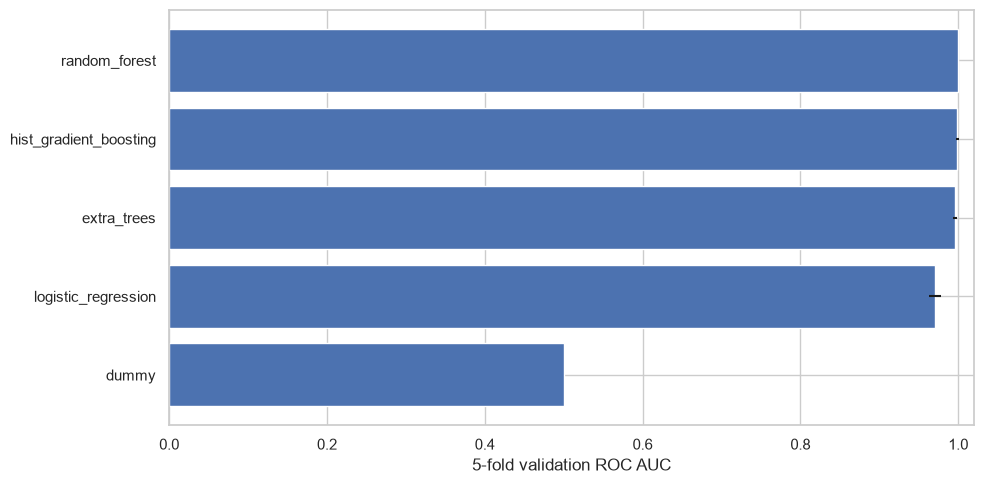

In [33]:
# Urutkan hasil evaluasi dan bandingkan ROC AUC setiap model.
cv_results = pd.DataFrame(comparison_rows).sort_values(
    ["cv_roc_auc_mean", "cv_f1_mean"], ascending=False
).reset_index(drop=True)
display(cv_results)
cv_results.to_csv(ARTIFACT_DIR / "model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(cv_results["model"], cv_results["cv_roc_auc_mean"], xerr=cv_results["cv_roc_auc_std"])
ax.set_xlabel("5-fold validation ROC AUC")
ax.set_xlim(0, 1.02)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [34]:
# Tentukan ruang parameter untuk model kandidat terbaik.
best_model_name = cv_results.loc[cv_results["model"].ne("dummy"), "model"].iloc[0]
parameter_spaces = {
    "logistic_regression": {"model__C": np.logspace(-3, 2, 15), "model__class_weight": [None, "balanced"]},
    "random_forest": {
        "model__n_estimators": [200, 400], "model__max_depth": [None, 8, 16],
        "model__min_samples_leaf": [1, 2, 4], "model__max_features": ["sqrt", 0.8],
    },
    "extra_trees": {
        "model__n_estimators": [200, 400], "model__max_depth": [None, 8, 16],
        "model__min_samples_leaf": [1, 2, 4], "model__max_features": ["sqrt", 0.8],
    },
    "hist_gradient_boosting": {
        "model__learning_rate": [0.03, 0.06, 0.1], "model__max_iter": [150, 250],
        "model__max_leaf_nodes": [15, 31], "model__min_samples_leaf": [10, 20, 30],
        "model__l2_regularization": [0.0, 1.0, 5.0],
    },
}

In [35]:
# Siapkan pencarian acak parameter dengan ROC AUC sebagai acuan.
search = RandomizedSearchCV(
    clone(pipelines[best_model_name]), parameter_spaces[best_model_name],
    n_iter=12, scoring=scoring, refit="roc_auc", cv=cv, n_jobs=-1,
    random_state=RANDOM_STATE, error_score="raise", return_train_score=True,
)

In [36]:
# Jalankan tuning tanpa membuat run MLflow tambahan.
search.fit(X_train, y_train)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 8, ...], 'model__max_features': ['sqrt', 0.8], 'model__min_samples_leaf': [1, 2, ...], 'model__n_estimators': [200, 400]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",12
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","{'accuracy': 'accuracy', 'balanced_accuracy': 'balanced_accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In alloth

In [37]:
# Tinjau dan simpan tabel hasil pencarian parameter.
tuning_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_roc_auc")
display(tuning_results[["rank_test_roc_auc", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_f1", "mean_train_roc_auc", "params"]].head(12))
tuning_results.to_csv(ARTIFACT_DIR / "hyperparameter_search.csv", index=False)
print({"model": best_model_name, "best_params": search.best_params_, "best_cv_roc_auc": search.best_score_})


,rank_test_roc_auc,mean_test_roc_auc,std_test_roc_auc,mean_test_f1,mean_train_roc_auc,params
0,1,1.0000,0.0000,0.9991,1.0000,"{'model__n_estimators': 400, 'model__min_sampl..."
11,1,1.0000,0.0000,0.9986,1.0000,"{'model__n_estimators': 200, 'model__min_sampl..."
8,3,0.9999,0.0001,0.9986,1.0000,"{'model__n_estimators': 200, 'model__min_sampl..."
6,4,0.9999,0.0001,0.9991,1.0000,"{'model__n_estimators': 400, 'model__min_sampl..."
10,4,0.9999,0.0001,0.9991,1.0000,"{'model__n_estimators': 400, 'model__min_sampl..."
3,6,0.9999,0.0001,0.9981,1.0000,"{'model__n_estimators': 200, 'model__min_sampl..."
5,7,0.9999,0.0001,0.9986,1.0000,"{'model__n_estimators': 400, 'model__min_sampl..."
9,8,0.9998,0.0002,0.9960,1.0000,"{'model__n_estimators': 400, 'model__min_sampl..."
7,9,0.9998,0.0004,0.9972,1.0000,"{'model__n_estimators': 200, 'model__min_sampl..."
4,10,0.9997,0.0003,0.9960,1.0000,"{'model__n_estimators': 200, 'model__min_sampl..."


{'model': 'random_forest', 'best_params': {'model__n_estimators': 400, 'model__min_samples_leaf': 4, 'model__max_features': 0.8, 'model__max_depth': 16}, 'best_cv_roc_auc': np.float64(0.9999598723210215)}


In [38]:
# Pilih hasil tuning jika mengungguli skor validasi awal.
baseline_cv_auc = float(cv_results.loc[cv_results["model"].eq(best_model_name), "cv_roc_auc_mean"].iloc[0])
if search.best_score_ >= baseline_cv_auc:
    best_pipeline = search.best_estimator_
    selected_parameters = search.best_params_
else:
    best_pipeline = clone(pipelines[best_model_name]).fit(X_train, y_train)
    selected_parameters = {}
print(best_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(sparse_threshold=0,
                                   transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['no_of_dependents',
                                                   'income_annum',
                                                   'loan_amount', 'loan_term',
                                                   'cibil_score',
                                                   'residential_assets_value',
                                           

In [39]:
# Hitung prediksi dan probabilitas untuk data latih serta data uji.
y_train_pred = best_pipeline.predict(X_train)
y_train_proba = best_pipeline.predict_proba(X_train)[:, list(best_pipeline.classes_).index(1)]
y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, list(best_pipeline.classes_).index(1)]

In [40]:
# Hitung metrik klasifikasi dan kualitas probabilitas.

def calculate_metrics(y_true, y_predicted, y_probability):
    return {
        "accuracy": float(accuracy_score(y_true, y_predicted)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_predicted)),
        "precision_approved": float(precision_score(y_true, y_predicted, zero_division=0)),
        "recall_approved": float(recall_score(y_true, y_predicted, zero_division=0)),
        "f1_approved": float(f1_score(y_true, y_predicted, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_true, y_probability)),
        "average_precision": float(average_precision_score(y_true, y_probability)),
        "log_loss": float(log_loss(y_true, y_probability)),
        "brier_score": float(brier_score_loss(y_true, y_probability)),
    }

In [41]:
# Bandingkan performa latih dan uji untuk melihat potensi overfit.
train_metrics = calculate_metrics(y_train, y_train_pred, y_train_proba)
test_metrics = calculate_metrics(y_test, y_pred, y_proba)
metrics = {
    "selected_model": best_model_name,
    "train_rows": len(y_train),
    "test_rows": len(y_test),
    "train": train_metrics,
    "test": test_metrics,
    "train_minus_test_gap": {
        metric: train_metrics[metric] - test_metrics[metric]
        for metric in train_metrics
    },
}
comparison = pd.DataFrame({"train": train_metrics, "test": test_metrics})
comparison["train_minus_test"] = comparison["train"] - comparison["test"]
display(comparison)

,train,test,train_minus_test
accuracy,0.9988,0.9977,0.0012
balanced_accuracy,0.9984,0.9969,0.0015
precision_approved,0.9981,0.9962,0.0019
recall_approved,1.0000,1.0000,0.0000
f1_approved,0.9991,0.9981,0.0009
roc_auc,1.0000,1.0000,-0.0000
average_precision,1.0000,1.0000,-0.0000
log_loss,0.0037,0.0069,-0.0031
brier_score,0.0008,0.0017,-0.0008


In [42]:
# Buat laporan klasifikasi terpisah untuk data latih dan uji.
train_report = pd.DataFrame(classification_report(
    y_train, y_train_pred, labels=[0, 1], target_names=["Rejected", "Approved"],
    zero_division=0, output_dict=True,
)).T
train_report["dataset"] = "train"
test_report = pd.DataFrame(classification_report(
    y_test, y_pred, labels=[0, 1], target_names=["Rejected", "Approved"],
    zero_division=0, output_dict=True,
)).T
test_report["dataset"] = "test"
report = pd.concat([train_report, test_report], axis=0)
display(report)
report.to_csv(ARTIFACT_DIR / "classification_report.csv")

,precision,recall,f1-score,support,dataset
Rejected,1.0000,0.9969,0.9984,"1,290.0000",train
Approved,0.9981,1.0000,0.9991,"2,125.0000",train
accuracy,0.9988,0.9988,0.9988,0.9988,train
macro avg,0.9991,0.9984,0.9988,"3,415.0000",train
weighted avg,0.9988,0.9988,0.9988,"3,415.0000",train
Rejected,1.0000,0.9938,0.9969,323.0000,test
Approved,0.9962,1.0000,0.9981,531.0000,test
accuracy,0.9977,0.9977,0.9977,0.9977,test
macro avg,0.9981,0.9969,0.9975,854.0000,test
weighted avg,0.9977,0.9977,0.9977,854.0000,test


In [43]:
# Catat seluruh eksperimen dalam satu run final di MLflow.

with mlflow.start_run(run_name=f"final_{best_model_name}") as final_run:
    mlflow.set_tags({"stage": "final_evaluation", "model_name": best_model_name})
    mlflow.log_params({
        "dataset": DATASET, "model_name": best_model_name,
        "decision_threshold": 0.5, "random_state": RANDOM_STATE,
        "train_rows": len(X_train), "test_rows": len(X_test),
        "cv_folds": cv.get_n_splits(), "tuning_iterations": 12,
    })
    mlflow.log_params({f"selected_{key}": str(value) for key, value in selected_parameters.items()})
    mlflow.log_params({f"tuned_{key}": str(value) for key, value in search.best_params_.items()})
    mlflow.log_metrics({f"train_{key}": float(value) for key, value in train_metrics.items()})
    mlflow.log_metrics({f"test_{key}": float(value) for key, value in test_metrics.items()})
    mlflow.log_metrics({f"train_minus_test_{key}": float(value) for key, value in metrics["train_minus_test_gap"].items()})
    mlflow.log_metric("best_tuning_cv_roc_auc", float(search.best_score_))

    # Catat hasil validasi semua kandidat di dalam run final yang sama.
    for _, row in cv_results.iterrows():
        for metric in scoring:
            mlflow.log_metric(f"{row['model']}_cv_{metric}", float(row[f"cv_{metric}_mean"]))
            mlflow.log_metric(f"{row['model']}_cv_{metric}_std", float(row[f"cv_{metric}_std"]))

    best_cv_row = cv_results.loc[cv_results["model"].eq(best_model_name)].iloc[0]
    for metric in scoring:
        mlflow.log_metric(f"selected_model_cv_{metric}", float(best_cv_row[f"cv_{metric}_mean"]))
    mlflow.sklearn.log_model(
        best_pipeline, artifact_path="model", input_example=X_train.head(3),
        serialization_format="cloudpickle",
    )
    final_mlflow_run_id = final_run.info.run_id
    final_mlflow_model_uri = f"runs:/{final_mlflow_run_id}/model"


2026/11/07 18:44:50 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/07 18:44:50 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\MSI-GF63\AppData\Local\Programs\Python\Python314\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes mis

In [44]:
# Lampirkan berkas pendukung ke eksperimen final MLflow.
for artifact in [
    DATA_DIR / "loan_approval_cleaned.csv",
    ARTIFACT_DIR / "cleaning_log.csv",
    ARTIFACT_DIR / "invalid_value_audit.csv",
    ARTIFACT_DIR / "training_outlier_report.csv",
    ARTIFACT_DIR / "model_comparison.csv",
    ARTIFACT_DIR / "hyperparameter_search.csv",
    ARTIFACT_DIR / "classification_report.csv",
]:
    if artifact.exists():
        mlflow.log_artifact(str(artifact), run_id=final_mlflow_run_id)

print({"mlflow_experiment": mlflow_experiment.name, "final_run_id": final_mlflow_run_id, "model_uri": final_mlflow_model_uri})

{'mlflow_experiment': 'loan-approval-prediction', 'final_run_id': '8d412e1bce194e918c2d8ab3945f9558', 'model_uri': 'runs:/8d412e1bce194e918c2d8ab3945f9558/model'}


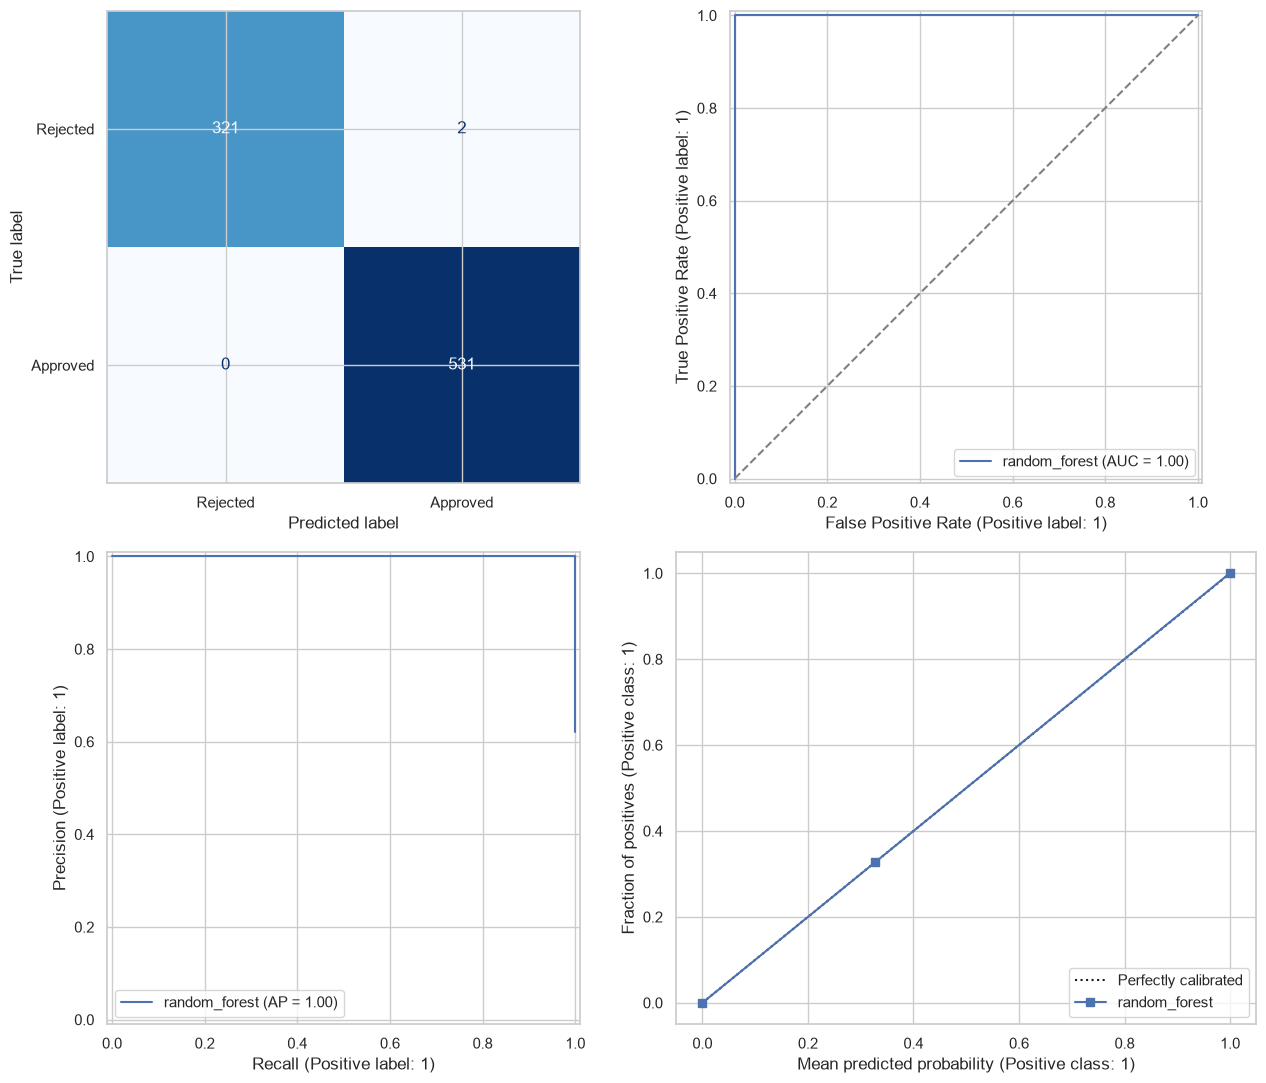

In [45]:
# Visualisasikan confusion matrix, ROC, precision-recall, dan kalibrasi.

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Rejected", "Approved"], cmap="Blues", colorbar=False, ax=axes[0, 0])
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0, 1], name=best_model_name)
axes[0, 1].plot([0, 1], [0, 1], linestyle="--", color="gray")
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[1, 0], name=best_model_name)
CalibrationDisplay.from_predictions(y_test, y_proba, n_bins=10, strategy="quantile", ax=axes[1, 1], name=best_model_name)

# Simpan grafik evaluasi dan lampirkan ke MLflow.
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "evaluation.png", dpi=150, bbox_inches="tight")
mlflow.log_artifact(str(ARTIFACT_DIR / "evaluation.png"), run_id=final_mlflow_run_id)
plt.show()

,feature,roc_auc_decrease_mean,roc_auc_decrease_std
6,cibil_score,0.4770,0.0123
5,loan_term,0.0095,0.0007
12,loan_to_income_ratio,0.0043,0.0008
13,assets_to_loan_ratio,0.0038,0.0000
8,commercial_assets_value,0.0000,0.0000
11,total_assets_value,0.0000,0.0000
0,no_of_dependents,0.0000,0.0000
3,income_annum,0.0000,0.0000
4,loan_amount,0.0000,0.0000
1,education,0.0000,0.0000


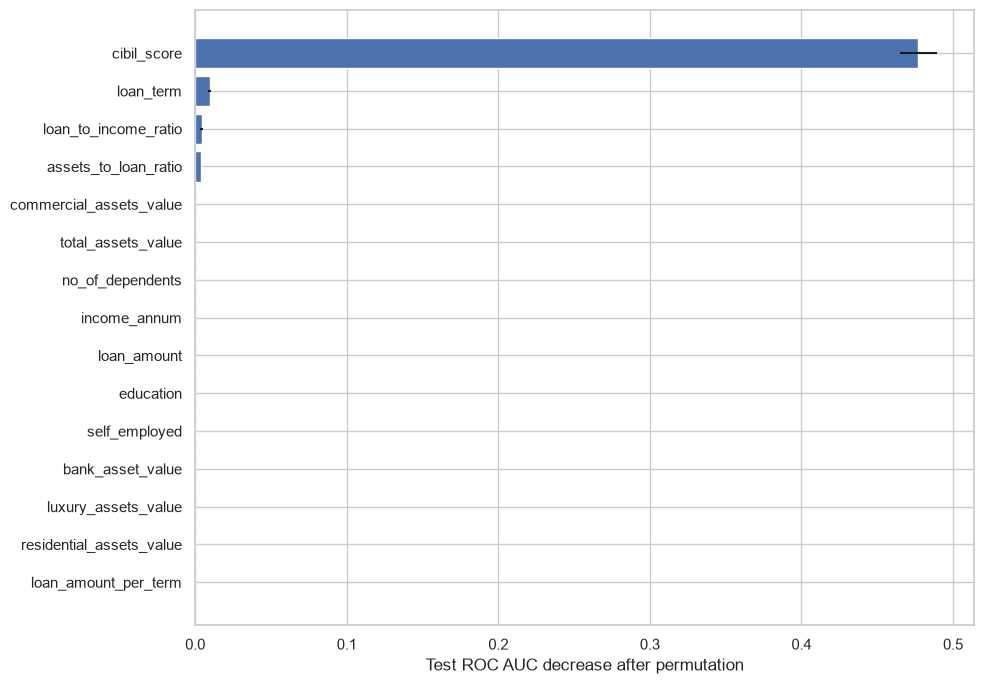

In [46]:
# Ukur kontribusi fitur lewat permutation importance pada data uji.

importance = permutation_importance(
    best_pipeline, X_test, y_test, scoring="roc_auc", n_repeats=5,
    random_state=RANDOM_STATE, n_jobs=-1,
)

# Susun skor kontribusi setiap fitur.
importance_df = pd.DataFrame({
    "feature": feature_columns,
    "roc_auc_decrease_mean": importance.importances_mean,
    "roc_auc_decrease_std": importance.importances_std,
}).sort_values("roc_auc_decrease_mean", ascending=False)
display(importance_df)
importance_df.to_csv(ARTIFACT_DIR / "permutation_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(importance_df["feature"], importance_df["roc_auc_decrease_mean"], xerr=importance_df["roc_auc_decrease_std"])
ax.set_xlabel("Test ROC AUC decrease after permutation")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
mlflow.log_artifact(str(ARTIFACT_DIR / "feature_importance.png"), run_id=final_mlflow_run_id)
plt.show()

In [47]:
# Tinjau hasil prediksi uji dan contoh kesalahan model.

test_predictions = X_test_raw.copy()
test_predictions["actual_loan_status"] = y_test.map(LABEL_MAP)
test_predictions["predicted_loan_status"] = pd.Series(y_pred, index=X_test.index).map(LABEL_MAP)
test_predictions["approval_probability"] = y_proba

# Pisahkan prediksi yang salah untuk ditinjau.
errors = test_predictions.loc[y_test.ne(pd.Series(y_pred, index=y_test.index))].copy()
errors["confidence"] = np.maximum(errors["approval_probability"], 1 - errors["approval_probability"])
display(errors.sort_values("confidence", ascending=False).head(20))
print({"incorrect_predictions": len(errors), "test_rows": len(y_test)})
test_predictions.to_csv(ARTIFACT_DIR / "test_predictions.csv", index=False)
errors.to_csv(ARTIFACT_DIR / "misclassified_applications.csv", index=False)
mlflow.log_artifact(str(ARTIFACT_DIR / "test_predictions.csv"), run_id=final_mlflow_run_id)
mlflow.log_artifact(str(ARTIFACT_DIR / "misclassified_applications.csv"), run_id=final_mlflow_run_id)

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,actual_loan_status,predicted_loan_status,approval_probability,confidence
1950,0.0000,graduate,yes,"200,000.0000","700,000.0000",10.0000,587.0000,NaN,"100,000.0000","500,000.0000","100,000.0000",Rejected,Approved,0.7284,0.7284
1039,5.0000,not graduate,no,"600,000.0000","2,300,000.0000",4.0000,347.0000,0.0000,0.0000,"1,900,000.0000","200,000.0000",Rejected,Approved,0.6602,0.6602


{'incorrect_predictions': 2, 'test_rows': 854}


In [48]:
# Simpan pipeline model terpilih untuk digunakan aplikasi.
joblib.dump(best_pipeline, ARTIFACT_DIR / "loan_approval_model.joblib")

['artifacts\\loan_approval_model.joblib']

In [49]:
# Simpan metadata model, data, fitur, dan kebijakan validasi.

metadata = {
    "dataset": DATASET,
    "dataset_url": f"https://www.kaggle.com/datasets/{DATASET}",
    "target": TARGET,
    "target_mapping": TARGET_MAP,
    "raw_features": X_train_raw.columns.tolist(),
    "model_features": feature_columns,
    "engineered_features": engineered_features,
    "split_random_state": RANDOM_STATE,
    "train_rows": len(X_train),
    "test_rows": len(X_test),
    "decision_threshold": 0.5,
    "selected_model": best_model_name,
    "selected_parameters": selected_parameters,
    "mlflow_tracking_uri": MLFLOW_URI,
    "mlflow_experiment_id": mlflow_experiment.experiment_id,
    "mlflow_final_run_id": final_mlflow_run_id,
    "mlflow_model_uri": final_mlflow_model_uri,
    "invalid_values": "Replaced by missing before splitting; imputation fitted in each training fold",
    "outlier_policy": "IQR flags reported from training data; valid extreme values retained",
    "model_training_data": "Training split only; holdout excluded from fitting and model selection",
}

In [50]:
# Simpan metrik dan metadata agar dapat dibaca oleh aplikasi.
with (ARTIFACT_DIR / "metrics.json").open("w", encoding="utf-8") as file:
    json.dump({"metrics": metrics, "cross_validation": cv_results.to_dict("records")}, file, indent=2)
with (ARTIFACT_DIR / "model_metadata.json").open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, default=str)

display(pd.DataFrame([
    {"file": str(path), "bytes": path.stat().st_size}
    for path in sorted(ARTIFACT_DIR.iterdir()) if path.is_file()
]))
mlflow.log_artifact(str(ARTIFACT_DIR / "metrics.json"), run_id=final_mlflow_run_id)
mlflow.log_artifact(str(ARTIFACT_DIR / "model_metadata.json"), run_id=final_mlflow_run_id)

,file,bytes
0,artifacts\classification_report.csv,805
1,artifacts\cleaning_log.csv,141
2,artifacts\evaluation.png,151100
3,artifacts\feature_importance.png,62180
4,artifacts\hyperparameter_search.csv,14179
5,artifacts\invalid_value_audit.csv,231
6,artifacts\loan_approval_model.joblib,785819
7,artifacts\metrics.json,4496
8,artifacts\misclassified_applications.csv,512
9,artifacts\model_comparison.csv,1350


In [51]:
# Uji pemuatan model, prediksi data baru, dan catatan run MLflow.

loaded_model = joblib.load(ARTIFACT_DIR / "loan_approval_model.joblib")
new_applications = X_test_raw.head(5).copy()
new_features = engineer_features(new_applications).reindex(columns=feature_columns)

# Buat prediksi contoh memakai model tersimpan.
new_probabilities = loaded_model.predict_proba(new_features)[:, list(loaded_model.classes_).index(1)]
inference_results = new_applications.copy()
inference_results["approval_probability"] = new_probabilities
inference_results["predicted_loan_status"] = pd.Series(
    loaded_model.predict(new_features), index=new_applications.index,
).map(LABEL_MAP)
display(inference_results)
mlflow_runs = mlflow.search_runs(
    experiment_ids=[mlflow_experiment.experiment_id],
    output_format="pandas",
    order_by=["start_time DESC"],
)
display(mlflow_runs[["tags.mlflow.runName", "status", "run_id", "start_time"]])
print({"tracking_uri": mlflow.get_tracking_uri(), "experiment": mlflow_experiment.name, "final_run_id": final_mlflow_run_id, "model_uri": final_mlflow_model_uri})

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,approval_probability,predicted_loan_status
2856,3.0000,not graduate,yes,"8,300,000.0000","31,400,000.0000",6.0000,674.0000,"1,000,000.0000","1,600,000.0000","17,200,000.0000","6,100,000.0000",0.1057,Rejected
3176,4.0000,not graduate,yes,"3,100,000.0000","8,200,000.0000",18.0000,408.0000,"2,900,000.0000","3,800,000.0000","10,800,000.0000","3,100,000.0000",0.0000,Rejected
477,1.0000,graduate,no,"8,000,000.0000","31,900,000.0000",12.0000,504.0000,"23,800,000.0000","1,500,000.0000","22,100,000.0000","6,000,000.0000",0.0000,Rejected
4023,0.0000,not graduate,no,"3,800,000.0000","13,300,000.0000",6.0000,655.0000,"9,600,000.0000",0.0000,"8,600,000.0000","2,600,000.0000",0.9990,Approved
134,3.0000,not graduate,no,"1,500,000.0000","5,500,000.0000",16.0000,717.0000,"2,100,000.0000","800,000.0000","4,400,000.0000","1,300,000.0000",1.0000,Approved


,tags.mlflow.runName,status,run_id,start_time
0,final_random_forest,FINISHED,8d412e1bce194e918c2d8ab3945f9558,2026-11-07 11:44:49.606000+00:00


{'tracking_uri': 'sqlite:///D:\\Python\\AI_Loan_prediction_Project\\mlflow.db', 'experiment': 'loan-approval-prediction', 'final_run_id': '8d412e1bce194e918c2d8ab3945f9558', 'model_uri': 'runs:/8d412e1bce194e918c2d8ab3945f9558/model'}
